# 3-04 기간 주목주 종합 — 시세·공시·뉴스를 합친 '주목도' 랭킹

**질문 예시:** "지금 시장에서 가장 주목받는 종목을 종합 점수로 랭킹해줘",
"이번 달 급등·거래폭증·변동성 다 합쳐서 주목주 상위 뽑아줘"

기간 수익률·최대 일간 변동·거래대금 증가율을 따로 보지 않고 **하나의 점수**로 줄 세운 뒤,
상위 종목에 공시를 붙여 왜 주목받는지 바로 읽습니다.

**각색·확장한 점:**
- CHECK 원본(`3_시세스크리너/04`)은 시세 지표 3개만 합쳤습니다. 여기서는 **공시 건수와 뉴스 증가율**을 더합니다.
  DeepSearch는 뉴스·공시에 종목 태그가 있어 `DocumentAggregation` **한 번 호출로 전 종목 건수**를 셉니다.
- 전 종목 시세는 거래일마다 한 번씩 받는 스냅샷(40회)으로 만듭니다. 코스닥도 전수입니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/3_price_screener/04_attention_composite.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        # 한 페이지가 count 보다 적게 와도(80~90건 흔함) 뒤에 더 있을 수 있다 → 총건수로 판단
        if not docs or page * count >= total:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"   # 기준일
PERIOD = 20           # 주목 기간(거래일) — 약 한 달
BASE = 20             # 비교 기준 구간(주목 기간 직전 거래일)
MIN_VALUE = 3e9       # 주목 기간 평균 거래대금 하한(30억)
TOP = 15
# 점수 가중치 (합이 1일 필요는 없음)
WEIGHTS = {"ret": 1.0, "move": 1.0, "value_x": 1.0, "disc": 0.5, "news_x": 0.5}

## 1. 전 종목 시세 패널 (40거래일)

In [4]:
idx = index_prices((pd.Timestamp(ASOF) - pd.Timedelta(days=90)).date(), ASOF)
days = sorted(idx["date"].dt.date.unique())[-(PERIOD + BASE):]
period_days, base_days = days[-PERIOD:], days[:BASE]
print(f"기준 구간 {base_days[0]} ~ {base_days[-1]} / 주목 기간 {period_days[0]} ~ {period_days[-1]}")

def stocks(day):
    """일반법인(1)·공기업(2) 보통주 전 종목 하루치. 헬퍼의 all_stocks(common_only=True)는 공기업 8종목
    (한국전력·기업은행·강원랜드 등, company_type_l1='2')을 빼므로 여기서 직접 거릅니다."""
    s = all_stocks(day, common_only=False)
    return s[s["company_type_l1"].isin(["1", "2"]) & s["symbol"].str.endswith("0")].reset_index(drop=True)

frames = []
for d in days:
    s = stocks(d)
    frames.append(s[s["date"].dt.date == d])
panel = pd.concat(frames, ignore_index=True)
panel = panel[panel["volume"] > 0]
panel["d"] = panel["date"].dt.date
print(panel.shape, "종목 수", panel["symbol"].nunique())

기준 구간 2026-09-28 ~ 2026-10-27 / 주목 기간 2026-10-28 ~ 2026-11-24


(104679, 21) 종목 수 2675


## 2. 시세 지표
- **기간 수익률**: 주목 기간 일별 등락률을 복리로 곱한 값(수정주가 기준)
- **최대 일간 변동**: 주목 기간 중 하루 |등락률| 최댓값
- **거래대금 증가 배수**: 주목 기간 평균 ÷ 기준 구간 평균

In [5]:
pp, bp = panel[panel["d"].isin(period_days)], panel[panel["d"].isin(base_days)]
gp = pp.groupby("symbol")
m = pd.DataFrame({
    "name": gp["name"].last(), "market": gp["market"].last(),
    "n_days": gp["d"].nunique(),
    "ret": gp["change_rate"].apply(lambda s: ((1 + s).prod() - 1) * 100),
    "move": gp["change_pct"].apply(lambda s: s.abs().max()),
    "value_p": gp["value"].mean(),
    "value_b": bp.groupby("symbol")["value"].mean(),
    "mcap": gp["market_cap"].last(),
})
m = m[(m["n_days"] >= PERIOD - 2) & (m["value_b"] > 0) & (m["value_p"] >= MIN_VALUE)].copy()
m["value_x"] = m["value_p"] / m["value_b"]
print("점수 대상 종목:", len(m))

점수 대상 종목: 470


## 3. 공시·뉴스 건수 (전 종목 한 번에)
`DocumentAggregation(..., "securities.symbol:N")`은 종목코드별 문서 수를 돌려줍니다.
- **공시 건수**: 주목 기간 공시(회사 공시 + 거래소 경보) 수
- **뉴스 증가 배수**: (주목 기간 뉴스 + 1) ÷ (기준 구간 뉴스 + 1).
  'DB', 'NEW', '영광'처럼 일반 단어와 같은 종목명은 관련 없는 기사까지 태그되어 절대 건수가 부풀려집니다.
  기준 구간도 같은 비율로 부풀려지므로 **증가 배수**로 쓰면 이 오탐이 상쇄됩니다.

In [6]:
def agg_by_symbol(category, section, date_from, date_to, size=3000):
    q = (f'DocumentAggregation(["{category}"],{json.dumps(section)},"*","securities.symbol:{size}",'
         f'date_from={date_from},date_to={date_to})')
    df = ds_df(q)
    if df.empty:
        return pd.Series(dtype=float)
    df = df[df["key"].str.fullmatch(r"\d{6}")]          # 상장사 6자리 코드만 (8자리는 DART 고유번호)
    return df.set_index("KRX:" + df["key"])["count"].astype(float)

disc_p = agg_by_symbol("company", ["disclosure"], period_days[0], period_days[-1])
news_p = agg_by_symbol("news", [], period_days[0], period_days[-1])
news_b = agg_by_symbol("news", [], base_days[0], base_days[-1])
print("태그된 종목 수 — 공시", len(disc_p), "/ 뉴스(기간)", len(news_p), "/ 뉴스(기준)", len(news_b))

m["disc"] = disc_p.reindex(m.index).fillna(0)
m["news_p"] = news_p.reindex(m.index).fillna(0)
m["news_b"] = news_b.reindex(m.index).fillna(0)
m["news_x"] = (m["news_p"] + 1) / (m["news_b"] + 1)

태그된 종목 수 — 공시 2112 / 뉴스(기간) 1714 / 뉴스(기준) 1641


## 4. 주목도 점수
각 지표를 전 종목 내 **백분위(0~100)**로 바꾼 뒤 가중 평균합니다. 수익률은 오른 쪽·내린 쪽 모두 주목이므로 절댓값을 씁니다.
점수는 종목 간 순위를 매기는 상대값입니다.

In [7]:
pct = pd.DataFrame({
    "ret": m["ret"].abs().rank(pct=True), "move": m["move"].rank(pct=True),
    "value_x": m["value_x"].rank(pct=True), "disc": m["disc"].rank(pct=True),
    "news_x": m["news_x"].rank(pct=True),
}) * 100
m["score"] = sum(pct[k] * w for k, w in WEIGHTS.items()) / sum(WEIGHTS.values())
top = m.sort_values("score", ascending=False).head(TOP).copy()
top["시총"] = top["mcap"].map(krw)
top["거래대금(억/일)"] = top["value_p"] / 1e8
print(PRICE_NOTICE)
top[["name", "market", "score", "ret", "move", "value_x", "거래대금(억/일)", "disc", "news_p", "news_x", "시총"]].round(1)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


,name,market,score,ret,move,value_x,거래대금(억/일),disc,news_p,news_x,시총
symbol,,,,,,,,,,,
KRX:180640,한진칼,KOSPI,96.1,88.5,30.0,16.5,1296.8,10.0,404.0,135.0,15.1조
KRX:069510,에스텍,KOSDAQ,94.5,65.4,30.0,27.2,33.9,8.0,5.0,6.0,"2,607억"
KRX:093320,케이아이엔엑스,KOSDAQ,92.0,43.6,30.0,3.5,47.7,10.0,3.0,4.0,"8,442억"
KRX:282720,금양그린파워,KOSDAQ,91.8,60.3,30.0,199.8,211.1,4.0,7.0,8.0,"1,325억"
KRX:272450,진에어,KOSPI,91.4,39.4,29.9,17.3,114.6,13.0,212.0,1.9,"3,931억"
KRX:446840,지슨,KOSDAQ,88.7,59.5,30.0,95.3,66.0,3.0,29.0,4.3,599억
KRX:267850,아시아나IDT,KOSPI,88.7,40.0,30.0,624.3,319.9,4.0,4.0,2.5,"1,412억"
KRX:263860,지니언스,KOSDAQ,86.7,68.6,30.0,10.2,870.8,8.0,112.0,0.9,"3,214억"
KRX:104620,노랑풍선,KOSDAQ,86.4,67.0,30.0,140.3,149.6,2.0,56.0,2.0,761억


## 5. 상위 종목의 공시 흐름
상위 종목을 묶어 한 번에 공시를 받아, 종목별로 시간순 제목을 이어 붙입니다.

In [8]:
codes = [s.split(":")[-1] for s in top.index]
_, docs = doc_search("company", ["disclosure"], "securities.symbol:(" + " or ".join(codes) + ")",
                     period_days[0], ASOF, count=100, pages=4)

def chain(code, n=4):
    if docs.empty:
        return "(공시 없음)"
    sub = docs[docs["symbols"].str.contains(code, na=False)].sort_values("created_at")
    t = sub["title"].drop_duplicates().tolist()
    return " → ".join(t[-n:]) if t else "(공시 없음)"

top["공시 흐름(최근 4건)"] = [chain(c) for c in codes]
top[["name", "score", "ret", "공시 흐름(최근 4건)"]].round(1)

,name,score,ret,공시 흐름(최근 4건)
symbol,,,,
KRX:180640,한진칼,96.1,88.5,(예고)단기과열종목 지정예고 → 특수관계인과의내부거래 → 분기보고서 (2026.09) → 기타경영사항...
KRX:069510,에스텍,94.5,65.4,[투자주의]투자경고종목 지정예고 → [투자주의]단일계좌 거래량 상위종목 → [투자주의]소수계좌 거래집...
KRX:093320,케이아이엔엑스,92.0,43.6,[기재정정]주식등의대량보유상황보고서(일반) → 연결재무제표기준영업(잠정)실적(공정공시) → 영업(잠정...
KRX:282720,금양그린파워,91.8,60.3,[기재정정]단일판매ㆍ공급계약체결 → 분기보고서 (2026.09) → 단일판매ㆍ공급계약체결
KRX:272450,진에어,91.4,39.4,[기재정정]주요사항보고서(회사합병결정) → 분기보고서 (2026.09) → [기재정정]주주총회소집결의...
KRX:446840,지슨,88.7,59.5,분기보고서 (2026.09) → [투자주의]투자경고종목 지정예고 → 투자경고종목지정
KRX:267850,아시아나IDT,88.7,40.0,[투자주의]투자경고종목 지정예고 → (예고)단기과열종목 지정예고 → 분기보고서 (2026.09) → ...
KRX:263860,지니언스,86.7,68.6,분기보고서 (2026.09) → 임원ㆍ주요주주특정증권등소유상황보고서 → 주식등의대량보유상황보고서(약식...
KRX:104620,노랑풍선,86.4,67.0,분기보고서 (2026.09) → (예고)단기과열종목 지정예고


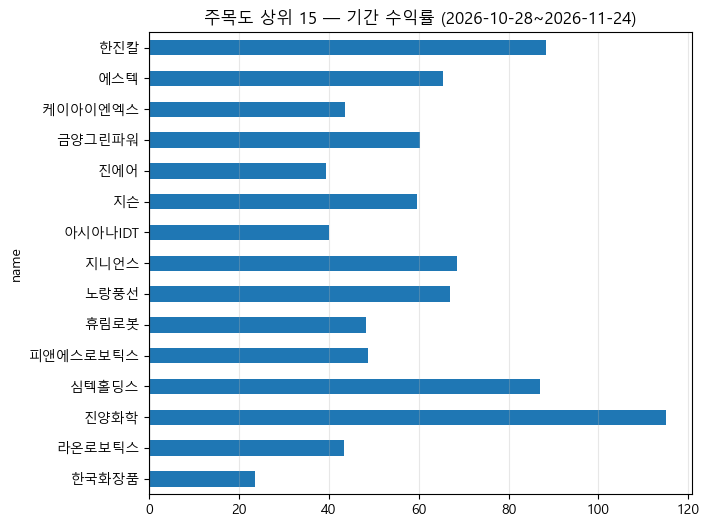

In [9]:
ax = top.set_index("name")[["ret"]].rename(columns={"ret": "기간 수익률(%)"}).iloc[::-1].plot.barh(
    figsize=(7, 6), legend=False, title=f"주목도 상위 {TOP} — 기간 수익률 ({period_days[0]}~{period_days[-1]})")
ax.axvline(0, color="gray", lw=.8); ax.grid(alpha=.3, axis="x")

## 결과 읽는 법과 한계
- 상위권은 **급등(또는 급락) + 거래 폭증 + 경보 공시**가 겹친 종목으로 채워집니다. 가중치(`WEIGHTS`)를 바꾸면
  "거래대금 급증 위주", "뉴스 화제 위주"처럼 성격을 바꿀 수 있습니다.
- 공시 건수에는 정기보고서·임원 지분 보고 같은 일상 공시도 섞입니다. 그래서 가중치를 시세 지표의 절반으로 두었습니다.
- 뉴스 종목 태그는 동명 종목 오탐이 있습니다(위 3절). 뉴스 증가 배수는 이를 줄이지만 없애지는 못합니다.
- 거래대금은 KRX 기준(NXT 미포함), 가격은 수정주가입니다.